<p align="center">
  <img src="https://raw.githubusercontent.com/udityamerit/Text-Processing-Package-For-Natural-Language-Processing/main/nlp_banner.png" alt="NLP Text Preprocessing" width="100%" />
</p>

# NLP Text Preprocessing: the Complete Hands-On Guide

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/udityamerit/Text-Processing-Package-For-Natural-Language-Processing/blob/main/examples/NLP_Text_Preprocessing_Complete_Guide.ipynb)
[![PyPI](https://img.shields.io/pypi/v/nlp-text-preprocessing)](https://pypi.org/project/nlp-text-preprocessing/)
[![Python](https://img.shields.io/pypi/pyversions/nlp-text-preprocessing)](https://pypi.org/project/nlp-text-preprocessing/)
[![License](https://img.shields.io/github/license/udityamerit/Text-Processing-Package-For-Natural-Language-Processing)](https://github.com/udityamerit/Text-Processing-Package-For-Natural-Language-Processing/blob/main/LICENSE)

Raw text is messy: URLs, HTML, emojis, typos, e-mail addresses, phone numbers and shouting. Before any model can learn from it, the text has to be cleaned and understood.

**`nlp-text-preprocessing`** is a small Python library that does this with plain functions, an easy-to-chain `Pipeline`, and no hidden downloads. This notebook walks through it **cell by cell**. Every cell is run, and its output is saved, so you can see exactly what each function does before you install anything.

### What you will learn

| Part | Topic |
| :-- | :-- |
| 1 | Install and set up |
| 2 | Safe inputs: `None` and `NaN` never crash |
| 3 | Feature extraction and readability scores |
| 4 | Cleaning and normalisation |
| 5 | Emojis and personal data (PII), including name masking |
| 6 | Linguistic tools: lemmas, entities, POS tags, keywords |
| 7 | Moderation and sentiment helpers (baselines) |
| 8 | The `Pipeline` engine: arguments, saving, fast batches |
| 9 | Pandas and scikit-learn |
| 10 | Preparing text for transformers (BERT, GPT, ...) |
| 11 | The `nlp-prep` command line |
| 12 | Word clouds |
| 13 | Cheat sheet |

*Written for `nlp-text-preprocessing` 0.5.1. Author: [Uditya Narayan Tiwari](https://udityanarayantiwari.netlify.app/).*

---
## Part 1. Install and set up

Install the package with the extras you need. `[all]` adds pandas, wordcloud, matplotlib, scikit-learn and transformers:

| Command | What you get |
| :-- | :-- |
| `pip install nlp-text-preprocessing` | the core library |
| `pip install "nlp-text-preprocessing[pandas]"` | + pandas helpers |
| `pip install "nlp-text-preprocessing[viz]"` | + word clouds |
| `pip install "nlp-text-preprocessing[sklearn]"` | + scikit-learn transformer |
| `pip install "nlp-text-preprocessing[transformers]"` | + HuggingFace tokenizers |
| `pip install "nlp-text-preprocessing[all]"` | everything optional |

In [1]:
%pip install -q --disable-pip-version-check -U "nlp-text-preprocessing[all]"

Note: you may need to restart the kernel to use updated packages.


Importing the package is **light and silent**: it loads no heavy library and downloads nothing. spaCy, TextBlob and NLTK data are loaded the first time a function needs them.

The one-time setup below downloads the NLTK data and the spaCy model (`en_core_web_sm`). Run it once per machine.

In [2]:
import nlp_text_preprocessing as tp

print("version:", tp.__version__)
tp.download_nltk_packages()          # one-time setup

version: 0.5.1


In [3]:
tp.check_resources(verbose=True)     # shows what is installed and what is missing

spaCy model 'en_core_web_sm': OK
NLTK 'punkt_tab' (TextBlob tokenization (noun phrases, tags, sentiment)): OK
NLTK 'wordnet' (get_synonyms / get_antonyms): OK
NLTK 'omw-1.4' (WordNet lookups on recent NLTK versions): OK


{'spacy_model': True,
 'nltk': {'punkt_tab': True, 'wordnet': True, 'omw-1.4': True}}

---
## Part 2. Safe inputs

Real datasets contain `None`, `NaN` and empty cells. Every function treats them as **empty text**, so a single bad row never stops a whole run.

In [4]:
import numpy as np

for bad in [None, np.nan, "", "   "]:
    print(repr(bad), "->", tp.word_count(bad), "words |", repr(tp.to_lower_case(bad)))

None -> 0 words | ''
nan -> 0 words | ''
'' -> 0 words | ''
'   ' -> 0 words | '   '


---
## Part 3. Feature extraction

Quick numeric facts about a text. These are useful as features for a classifier, or just for understanding your data.

In [5]:
text = ("NLP is amazing! I tested it on 3 datasets, and it finished in 2 minutes. "
        "Follow @udityamerit and read more at #NLP.")

print("words            :", tp.word_count(text))
print("characters       :", tp.char_count(text))
print("avg word length  :", tp.avg_word_len(text))
print("stop words       :", tp.stop_words_count(text))
print("sentences        :", tp.sentence_count(text))
print("avg sentence len :", tp.avg_sentence_len(text))
print("hashtags         :", tp.hashtags_count(text))
print("mentions         :", tp.mentions_count(text))
print("numbers          :", tp.numerics_count(text))
print("unique word ratio:", tp.unique_word_ratio(text))
print("capital ratio    :", tp.capital_ratio(text))

words            : 22
characters       : 94
avg word length  : 4.2727272727272725
stop words       : 10
sentences        : 3
avg sentence len : 7.333333333333333
hashtags         : 1
mentions         : 1
numbers          : 2
unique word ratio: 0.9090909090909091
capital ratio    : 0.09090909090909091


`text_stats` returns all of them at once as a dictionary:

In [6]:
tp.text_stats(text)

{'word_count': 22,
 'char_count': 94,
 'avg_word_len': 4.2727272727272725,
 'sentence_count': 3,
 'avg_sentence_len': 7.333333333333333,
 'stop_words_count': 10,
 'hashtags_count': 1,
 'mentions_count': 1,
 'numerics_count': 2,
 'upper_case_count': 2,
 'punctuation_density': 0.05217391304347826,
 'capital_ratio': 0.09090909090909091,
 'unique_word_ratio': 0.9090909090909091,
 'readability_score': 60.96}

### New in 0.5.0: `readability_scores`

`readability_score` gives one number (Flesch Reading Ease). `readability_scores` gives **five measures in one dictionary**:

| Key | Meaning |
| :-- | :-- |
| `flesch_reading_ease` | higher = easier to read |
| `flesch_kincaid_grade` | US school grade needed |
| `gunning_fog` | years of education needed |
| `automated_readability_index` | US grade, based on characters |
| `coleman_liau` | US grade, based on letters |

The scores are approximate and meant for English.

In [7]:
easy = "I like my dog. He is very big. We play in the park every day."
hard = ("The committee announced its decision after a long debate. Many members said they were worried "
        "about rising prices and what they might mean for families next year.")

import pandas as pd
pd.DataFrame({"easy": tp.readability_scores(easy), "news": tp.readability_scores(hard)}).round(2)

,easy,news
flesch_reading_ease,100.24,61.53
flesch_kincaid_grade,0.52,8.03
gunning_fog,4.67,9.84
automated_readability_index,-5.11,8.70
coleman_liau,-4.47,11.19


The news-style text scores lower on Flesch (harder to read) and higher on every grade-level measure, about grade 8 here. Empty text returns `0.0` for every key.

---
## Part 4. Cleaning and normalisation

Each cleaning function does **one job**. Here is a messy social-media post:

In [8]:
raw = ("<p>RT @user: Check out https://example.com NOW!!! Email me: support@company.org, "
       "call +1 415-555-0199. I'm soooo happy 😂 #MachineLearning2024 — it's café time…</p>")
print(raw)

<p>RT @user: Check out https://example.com NOW!!! Email me: support@company.org, call +1 415-555-0199. I'm soooo happy 😂 #MachineLearning2024 — it's café time…</p>


In [9]:
print("remove_html_tag      :", tp.remove_html_tag(raw))
print()
print("remove_rt            :", tp.remove_rt(raw))
print("remove_urls          :", tp.remove_urls(raw))
print("remove_emails        :", tp.remove_emails(raw))
print("remove_phone_numbers :", tp.remove_phone_numbers(raw))
print("remove_mentions      :", tp.remove_mentions(raw))
print("remove_emojis        :", tp.remove_emojis(raw))

remove_html_tag      : RT @user: Check out https://example.com NOW!!! Email me: support@company.org, call +1 415-555-0199. I'm soooo happy 😂 #MachineLearning2024 — it's café time…

remove_rt            : <p> Check out https://example.com NOW!!! Email me: support@company.org, call +1 415-555-0199. I'm soooo happy 😂 #MachineLearning2024 — it's café time…</p>
remove_urls          : <p>RT @user: Check out  NOW!!! Email me: support@company.org, call +1 415-555-0199. I'm soooo happy 😂 #MachineLearning2024 — it's café time…</p>
remove_emails        : <p>RT @user: Check out https://example.com NOW!!! Email me: , call +1 415-555-0199. I'm soooo happy 😂 #MachineLearning2024 — it's café time…</p>
remove_phone_numbers : <p>RT @user: Check out https://example.com NOW!!! Email me: support@company.org, call . I'm soooo happy 😂 #MachineLearning2024 — it's café time…</p>
remove_mentions      : <p>RT : Check out https://example.com NOW!!! Email me: support@company.org, call +1 415-555-0199. I'm soooo ha

In [10]:
print("expand_hashtags              :", tp.expand_hashtags("#MachineLearning2024 and #NLPIsFun"))
print("contraction_to_expansion     :", tp.contraction_to_expansion("I'm sure we can't miss it, they'll love it"))
print("remove_repeated_chars        :", tp.remove_repeated_chars("I'm soooo happyyyy"))
print("remove_accented_chars        :", tp.remove_accented_chars("café, naïve, résumé"))
print("normalize_unicode_punctuation:", tp.normalize_unicode_punctuation("“smart quotes” — and… dashes"))
print("remove_numbers               :", tp.remove_numbers("I have 3 cats, 12 dogs and H2O on the 3rd floor"))
print("remove_currency_symbols      :", tp.remove_currency_symbols("It costs $20, €15 or £12"))
print("remove_special_chars         :", tp.remove_special_chars("well-known, state-of-the-art!!! (really)"))
print("remove_extra_whitespace      :", repr(tp.remove_extra_whitespace("too    many\n\n spaces\t here")))

expand_hashtags              : Machine Learning 2024 and NLP Is Fun
contraction_to_expansion     : I am sure we cannot miss it, they will love it
remove_repeated_chars        : I'm soo happyy
remove_accented_chars        : cafe, naive, resume
normalize_unicode_punctuation: "smart quotes" - and... dashes
remove_numbers               : I have  cats,  dogs and H2O on the 3rd floor
remove_currency_symbols      : It costs 20, 15 or 12
remove_special_chars         : well known state of the art really
remove_extra_whitespace      : 'too many spaces here'


Stop-word removal keeps **negations** by default, so `not good` does not turn into `good`:

In [11]:
sentence = "This is not a good movie and I do not like it"
print("default            :", tp.remove_stop_words(sentence))
print("keep_negations=False:", tp.remove_stop_words(sentence, keep_negations=False))

default            : not good movie not like
keep_negations=False: good movie like


### One call for everything: `clean_text`

`clean_text` runs the classic recipe in a sensible order: HTML, URLs, e-mails, lower-case, contractions, punctuation and lemmatisation.

In [12]:
tp.clean_text(raw)

'retweet user check out now email me call 1 415 555 0199 i be soooo happy machinelearning2024 it be café time'

In [13]:
tp.clean_text(raw, remove_stopwords=True)

'retweet user check email 1 415 555 0199 soooo happy machinelearning2024 café time'

### Gentler cleaning: `light_clean`

Transformer models such as BERT work best when you **keep** case and punctuation. `light_clean` only fixes the damage: Unicode, invisible characters, HTML, and URLs/e-mails/mentions (which you can remove, replace or keep).

In [14]:
messy = "<b>Great</b> &amp; fast!\u200b Visit https://example.com or mail me@site.com  @bob \x07"

print("light_clean default :", tp.light_clean(messy))
print("with placeholders   :", tp.light_clean(messy, urls="[URL]", emails="[EMAIL]", mentions="[USER]"))

light_clean default : Great & fast! Visit or mail @bob
with placeholders   : Great & fast! Visit [URL] or mail [EMAIL] [USER]


---
## Part 5. Emojis and personal data (PII)

### Emojis
Flags, skin tones and joined (ZWJ) emojis are handled with the `emoji` package.

In [15]:
post = "Launch day 🚀🔥 thanks team 👩🏽‍💻 🇮🇳 😂"

print("extract_emojis:", tp.extract_emojis(post))
print("emoji_to_text :", tp.emoji_to_text(post))
print("remove_emojis :", tp.remove_emojis(post))

extract_emojis: ['🚀', '🔥', '👩🏽\u200d💻', '🇮🇳', '😂']
emoji_to_text : Launch day rocket fire thanks team woman_technologist_medium_skin_tone India face_with_tears_of_joy
remove_emojis : Launch day  thanks team   


### Masking personal data: `mask_pii`

Replaces e-mail addresses, Luhn-valid card numbers, US SSNs and phone numbers with a token. Handy before you share or log text.

In [16]:
private = ("Barack Obama emailed me at obama@example.com. Card 4111 1111 1111 1111, "
           "SSN 123-45-6789, phone +1 415-555-0199.")

tp.mask_pii(private)

'Barack Obama emailed me at [REDACTED]. Card [REDACTED], SSN [REDACTED], phone [REDACTED].'

### New in 0.5.0: `names=True`

Names are **not** masked by default. Turn on `names=True` to also redact people's names, using spaCy's entity recogniser. You can pick your own placeholder with `token=`.

Name detection is statistical, so it can miss unusual names or mask a word that is not a name. Review the result when privacy matters.

In [17]:
print(tp.mask_pii(private, names=True))
print()
print(tp.mask_pii(private, token="<PII>", names=True))

[REDACTED] emailed me at [REDACTED]. Card [REDACTED], SSN [REDACTED], phone [REDACTED].

<PII> emailed me at <PII>. Card <PII>, SSN <PII>, phone <PII>.


---
## Part 6. Linguistic tools

These use spaCy, TextBlob and NLTK under the hood, loaded the first time you call them.

In [18]:
sentence = "Elon Musk visited Berlin in March, and the engineers were building new electric cars."

print("lemmatize     :", tp.lemmatize(sentence))
print("convert_to_base:", tp.convert_to_base(sentence))
print("singularize   :", tp.singularize_words(sentence))
print("pluralize     :", tp.pluralize_words("one engineer built a car"))

lemmatize     : Elon Musk visit Berlin in March, and the engineer be build new electric car.
convert_to_base: Elon Musk visit Berlin in March, and the engineer were build new electric car.
singularize   : Elon Musk visited Berlin in March, and the engineer were building new electric car.
pluralize     : one engineers built a cars


In [19]:
print("Named entities:")
for ent in tp.extract_entities(sentence):
    print("  ", ent)

Named entities:
   ('Elon Musk', 'PERSON')
   ('Berlin', 'GPE')
   ('March', 'DATE')


In [20]:
print("POS tags (first 6):")
for item in tp.extract_pos_tags(sentence)[:6]:
    print("  ", item)

print()
print("Dependency tree (first 6):")
for item in tp.get_dependency_tree(sentence)[:6]:
    print("  ", item)

POS tags (first 6):
   ('Elon', 'PROPN', 'NNP')
   ('Musk', 'PROPN', 'NNP')
   ('visited', 'VERB', 'VBD')
   ('Berlin', 'PROPN', 'NNP')
   ('in', 'ADP', 'IN')
   ('March', 'PROPN', 'NNP')

Dependency tree (first 6):
   ('Elon', 'compound', 'Musk')
   ('Musk', 'nsubj', 'visited')
   ('visited', 'ROOT', 'visited')
   ('Berlin', 'dobj', 'visited')
   ('in', 'prep', 'visited')
   ('March', 'pobj', 'in')


In [21]:
print("Noun phrases     :", tp.get_noun_phrase(sentence))
print("Noun chunks      :", [(c["phrase"], c["start"], c["end"]) for c in tp.chunk_noun_phrases(sentence)])
print("Bigrams (first 4):", tp.n_grams(sentence, n=2)[:4])

Noun phrases     : ['elon musk', 'berlin', 'march', 'new electric cars']
Noun chunks      : [('Elon Musk', 0, 9), ('Berlin', 18, 24), ('March', 28, 33), ('the engineers', 39, 52), ('new electric cars', 67, 84)]
Bigrams (first 4): [('Elon', 'Musk'), ('Musk', 'visited'), ('visited', 'Berlin'), ('Berlin', 'in')]


In [22]:
article = ("Natural language processing helps computers understand human language. "
           "Language models learn patterns from text, and text preprocessing makes those models "
           "faster and more accurate.")

print("Keywords  :", tp.keyword_extraction(article, top_n=5))
print("Similarity:", round(tp.text_similarity("I love natural language processing",
                                              "I enjoy natural language processing"), 3))

Keywords  : ['language', 'models', 'text', 'natural', 'processing']
Similarity: 0.667


In [23]:
for sample in ["This library makes text cleaning easy.",
               "Bonjour, comment allez-vous aujourd'hui ?",
               "यह एक हिंदी वाक्य है"]:
    print(tp.detect_language(sample), "<-", sample)

en <- This library makes text cleaning easy.
fr <- Bonjour, comment allez-vous aujourd'hui ?
hi <- यह एक हिंदी वाक्य है


In [24]:
print("synonyms of 'happy'  :", tp.get_synonyms("happy")[:8])
print("antonyms of 'happy'  :", tp.get_antonyms("happy"))
print("correct_spelling     :", tp.correct_spelling("I havv a speling mistke in thiss sentense."))

synonyms of 'happy'  : ['felicitous', 'glad', 'well-chosen']
antonyms of 'happy'  : ['unhappy']
correct_spelling     : I have a spelling mistake in this sentence.


---
## Part 7. Moderation and sentiment helpers

> **Be honest about the limits.** The profanity, toxicity, spam and emotion helpers are transparent **keyword baselines**, not a moderation system. They are great for exploring data and for building a quick first filter. For anything high-stakes, use a trained model and a human in the loop.

### Profanity

In [25]:
print(tp.detect_profanity("This is a clean sentence."))
print(tp.detect_profanity("What a sh1tty day"))              # leetspeak and word endings
print(tp.detect_profanity("Welcome to Hell's Kitchen"))      # not flagged
print(tp.censor_profanity("What a shitty, damn day", mask_char="#"))
print(tp.detect_profanity("damn it", include_mild=False))    # ignore mild words

False
True
False
What a ######, #### day
False


### Toxicity, with an explanation

In [26]:
for t in ["You are a stupid idiot",
          "I do not hate you",
          "Please kill the process and take out the trash"]:
    print(f"{tp.detect_toxicity(t):.2f}  <-  {t}")

0.65  <-  You are a stupid idiot
0.00  <-  I do not hate you
0.00  <-  Please kill the process and take out the trash


In [27]:
tp.toxicity_report("You are a stupid idiot and I hate you")

{'score': 0.8232,
 'matches': [{'word': 'stupid', 'weight': 1.0, 'targeted': True},
  {'word': 'idiot', 'weight': 0.5, 'targeted': False},
  {'word': 'hate', 'weight': 1.0, 'targeted': True}],
 'ignored': []}

`toxicity_report` explains **why** a score was given: which words matched, how much each weighs, and which negated words were ignored.

### Spam signals, sentiment and emotion

In [28]:
print(tp.detect_spam_signals("WIN NOW!!! Click here to buy now: http://spam.example.com"))
print(tp.detect_spam_signals("Hi!"))

{'excessive_caps': False, 'excessive_punctuation': True, 'has_url': True, 'spam_phrases': ['buy now', 'click here'], 'is_spam_candidate': True}
{'excessive_caps': False, 'excessive_punctuation': False, 'has_url': False, 'spam_phrases': [], 'is_spam_candidate': False}


In [29]:
for t in ["I absolutely love this library, it is wonderful!",
          "This is the worst experience ever.",
          "The meeting is at 3 pm."]:
    print(tp.sentiment_analysis(t), tp.polarity_subjectivity(t), "<-", t)

pos {'polarity': 0.75, 'subjectivity': 0.8} <- I absolutely love this library, it is wonderful!
neg {'polarity': -1.0, 'subjectivity': 1.0} <- This is the worst experience ever.
neu {'polarity': 0.0, 'subjectivity': 0.0} <- The meeting is at 3 pm.


In [30]:
print(tp.emotion_detection("I loved the trip but I was worrying about the cost"))
print(tp.emotion_detection("I am not happy about this"))

{'joy': 1, 'anger': 0, 'sadness': 0, 'fear': 1}
{'joy': 0, 'anger': 0, 'sadness': 0, 'fear': 0}


---
## Part 8. The `Pipeline` engine

A `Pipeline` chains steps by name. Build it once, then reuse it for a single text, a list, or a whole column.

In [31]:
pipe = tp.Pipeline([
    "remove_html_tag",
    "remove_urls",
    "remove_emails",
    "expand_hashtags",
    "to_lower_case",
    "remove_extra_whitespace",
    "lemmatize",
])
pipe

Pipeline(['remove_html_tag', 'remove_urls', 'remove_emails', 'expand_hashtags', 'to_lower_case', 'remove_extra_whitespace', 'lemmatize'])

In [32]:
pipe.run("Check out #MachineLearning at https://example.com! Mail me: hi@test.com")

'check out machine learn at ! mail me:'

A zero-config pipeline is available as `Pipeline.default()`:

In [33]:
default_pipe = tp.Pipeline.default()
print(default_pipe)
default_pipe.run("<p>I can't believe it's FREE!!! Visit https://example.com</p>")

Pipeline(['remove_html_tag', 'remove_urls', 'remove_emails', 'to_lower_case', 'contraction_to_expansion', 'remove_special_chars', 'remove_extra_whitespace'])


'i cannot believe it is free visit'

### Steps with arguments

Pass a step as `(name, {argument: value})`. Arguments are checked when the pipeline is **built**, so a typo fails immediately instead of halfway through a big job.

In [34]:
custom = tp.Pipeline([
    "to_lower_case",
    ("remove_stop_words", {"keep_negations": False}),
    ("mask_pii", {"token": "<PII>"}),
])
custom.run("This is NOT my email: someone@example.com")

'email: <PII>'

In [35]:
try:
    tp.Pipeline([("remove_stop_words", {"wrong_option": 1})])
except Exception as err:
    print(type(err).__name__, "->", err)

TypeError -> Bad arguments for pipeline step 'remove_stop_words': got an unexpected keyword argument 'wrong_option'


### Save and load

Save a pipeline to JSON and share it, so everyone in a team cleans text in exactly the same way.
(Custom Python functions must be registered with `@tp.register_step("name")` to be saved.)

In [36]:
import os, tempfile

path = os.path.join(tempfile.mkdtemp(), "my_pipeline.json")
custom.save(path)
print(open(path).read())

loaded = tp.Pipeline.load(path)
print(loaded.run("This is NOT my email: someone@example.com"))

{
  "version": 1,
  "steps": [
    "to_lower_case",
    {
      "step": "remove_stop_words",
      "args": {
        "keep_negations": false
      }
    },
    {
      "step": "mask_pii",
      "args": {
        "token": "<PII>"
      }
    }
  ]
}
email: <PII>


In [37]:
@tp.register_step("shout")
def shout(text):
    return text.upper() + "!"

p = tp.Pipeline(["remove_urls", "shout"])
print(p.run("hello https://example.com world"))

HELLO  WORLD!


### New in 0.5.0: faster batches

`run_batch` and `run_series` process the **spaCy steps** (`lemmatize`, `convert_to_base`, `singularize_words`, `pluralize_words`) with spaCy's `nlp.pipe`, which is much faster than looping over `run`. The output is identical.

Let's check both claims on 600 texts:

In [38]:
import time

texts = ["The engineers were building faster models and testing new features every day."] * 600
pipe_fast = tp.Pipeline(["to_lower_case", "lemmatize"])

pipe_fast.run_batch(texts[:5])             # warm-up: loads the spaCy model once

t0 = time.perf_counter()
looped = [pipe_fast.run(t) for t in texts]
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
batched = pipe_fast.run_batch(texts)
t_batch = time.perf_counter() - t0

print(f"loop over run()  : {t_loop:.2f} s")
print(f"run_batch()      : {t_batch:.2f} s   ({t_loop / t_batch:.1f}x faster)")
print("identical output :", looped == batched)

loop over run()  : 0.73 s
run_batch()      : 0.30 s   (2.4x faster)
identical output : True


### `diff_report`

Summarise what a pipeline did to a whole dataset:

In [39]:
before = ["Visit https://a.com NOW!!!", "Mail bob@x.com for <b>details</b>", None]
after = tp.Pipeline.default().run_batch(before)
print(after)
tp.diff_report(before, after)

['visit now', 'mail for details', '']


{'total_items': 3,
 'chars_before': 59,
 'chars_after': 25,
 'char_reduction_pct': 57.63,
 'words_before': 7,
 'words_after': 5,
 'word_reduction_pct': 28.57,
 'emails_removed': 1,
 'urls_removed': 1}

---
## Part 9. Pandas and scikit-learn

### Pandas

Every function works with `.apply()`, and `Pipeline.run_series` keeps the index and the name of your Series.

In [40]:
import pandas as pd

df = pd.DataFrame({"text": [
    "I'm loving this NLP package! #awesome",
    "Contact me at info@test.com or visit https://test.com",
    None,
    "<p>Terrible support. NEVER buying again!!!</p>",
]})

df["clean"] = tp.Pipeline.default().run_series(df["text"])
df["words"] = df["text"].apply(tp.word_count)
df

,text,clean,words
0,I'm loving this NLP package! #awesome,i am loving this nlp package awesome,6
1,Contact me at info@test.com or visit https://t...,contact me at or visit,7
2,NaN,,0
3,<p>Terrible support. NEVER buying again!!!</p>,terrible support never buying again,5


In [41]:
tp.text_stats_batch(df, "text").round(2)

,word_count,char_count,avg_word_len,sentence_count,avg_sentence_len,stop_words_count,hashtags_count,mentions_count,numerics_count,upper_case_count,punctuation_density,capital_ratio,unique_word_ratio,readability_score
0,6.0,32.0,5.33,2.0,3.0,1.0,1.0,0.0,0.0,1.0,0.08,0.17,1.0,62.79
1,7.0,47.0,6.71,1.0,7.0,3.0,0.0,0.0,0.0,0.0,0.11,0.00,1.0,42.62
2,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.00
3,5.0,42.0,8.40,2.0,2.5,1.0,0.0,0.0,0.0,1.0,0.20,0.20,1.0,35.10


### scikit-learn

`TextPreprocessor` is a scikit-learn transformer, so your cleaning lives **inside** the model pipeline and is applied the same way at training and prediction time.

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline as SkPipeline

reviews = [
    "I love this product, it works great!", "Absolutely fantastic quality, very happy",
    "Best purchase ever, highly recommend https://shop.example.com", "Wonderful support and fast delivery",
    "Terrible, it broke after one day", "Awful quality, I want a refund",
    "Worst purchase ever, do not buy", "Very disappointed, slow and rude support",
]
labels = [1, 1, 1, 1, 0, 0, 0, 0]

model = SkPipeline([
    ("clean", tp.TextPreprocessor(["to_lower_case", "remove_urls", "remove_special_chars", "lemmatize"])),
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression()),
])
model.fit(reviews, labels)

for t in ["What a great product, I love it!", "Awful, broke immediately. I want my money back!"]:
    print(model.predict([t])[0], "<-", t)

1 <- What a great product, I love it!
0 <- Awful, broke immediately. I want my money back!


---
## Part 10. Preparing text for transformers

Language models have a **token limit**. `truncate_text` keeps the first part; `chunk_text` splits a long document into overlapping pieces so no information is lost.

Without a tokenizer, tokens are whitespace words. With a HuggingFace tokenizer (`pip install "nlp-text-preprocessing[transformers]"`), the limits are counted in the model's own tokens:

```python
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
tp.truncate_text(text, 512, tokenizer=tok)
tp.chunk_text(text, 512, overlap=64, tokenizer=tok)
```

In [43]:
doc = " ".join(f"word{i}" for i in range(1, 31))     # a 30-word document

print("truncate_text:", tp.truncate_text(doc, max_tokens=8))
print()
for i, piece in enumerate(tp.chunk_text(doc, max_tokens=12, overlap=4), 1):
    print(f"chunk {i}:", piece)

truncate_text: word1 word2 word3 word4 word5 word6 word7 word8

chunk 1: word1 word2 word3 word4 word5 word6 word7 word8 word9 word10 word11 word12
chunk 2: word9 word10 word11 word12 word13 word14 word15 word16 word17 word18 word19 word20
chunk 3: word17 word18 word19 word20 word21 word22 word23 word24 word25 word26 word27 word28
chunk 4: word25 word26 word27 word28 word29 word30


---
## Part 11. The `nlp-prep` command line

Installing the package also installs a command, `nlp-prep` (the same as `python -m nlp_text_preprocessing`). It cleans text files, CSV columns, or standard input and output, with no Python code.

| Example | What it does |
| :-- | :-- |
| `nlp-prep clean in.txt -o out.txt` | one document per line |
| `nlp-prep clean data.csv -c review` | cleans a CSV column into a new column |
| `nlp-prep clean - < in.txt` | standard input to standard output |
| `nlp-prep clean in.txt --mode standard` | classic cleaning instead of light cleaning |
| `nlp-prep clean in.txt --steps to_lower_case,remove_urls` | your own steps |
| `nlp-prep clean in.txt --pipeline my_pipeline.json` | a saved `Pipeline` |
| `nlp-prep resources --download` | check or install NLTK data and the spaCy model |

Here it is running on a small CSV file:

In [44]:
import csv, subprocess, sys, tempfile, pathlib

work = pathlib.Path(tempfile.mkdtemp())
src = work / "reviews.csv"
with open(src, "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["id", "review"])
    w.writerow([1, "<b>Great</b> product!! Visit https://shop.example.com"])
    w.writerow([2, "Mail me at hi@test.com &amp; thanks"])

def nlp_prep(*args):
    shown = " ".join("reviews.csv" if a == str(src) else a for a in args)
    print("$ nlp-prep", shown)
    result = subprocess.run([sys.executable, "-m", "nlp_text_preprocessing", *args],
                            capture_output=True, text=True, encoding="utf-8")
    print(result.stdout or result.stderr)

nlp_prep("--version")
nlp_prep("clean", str(src), "-c", "review", "--url-token", "[URL]", "--email-token", "[EMAIL]")

$ nlp-prep --version


nlp-prep 0.5.1

$ nlp-prep clean reviews.csv -c review --url-token [URL] --email-token [EMAIL]


id,review,review_clean
1,<b>Great</b> product!! Visit https://shop.example.com,Great product!! Visit [URL]
2,Mail me at hi@test.com &amp; thanks,Mail me at [EMAIL] & thanks



---
## Part 12. Word clouds

`get_wordcloud` builds a `WordCloud` object. Use `save_path=` to write a PNG, and `show=False` to avoid opening a window.

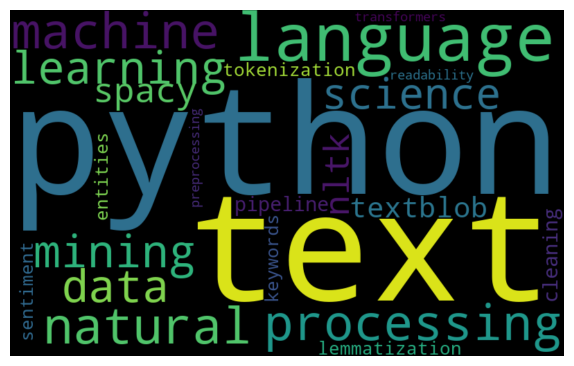

In [45]:
import matplotlib.pyplot as plt

corpus = ("python natural language processing machine learning text mining data science "
          "spacy nltk textblob pipeline cleaning lemmatization tokenization sentiment "
          "entities keywords readability preprocessing transformers python python text text language")

wc = tp.get_wordcloud(corpus, show=False)

plt.figure(figsize=(9, 4.5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

---
## Part 13. Cheat sheet

| I want to... | Use |
| :-- | :-- |
| Clean text in one call | `tp.clean_text(text)` |
| Clean gently for BERT/GPT | `tp.light_clean(text)` |
| Build a reusable cleaner | `tp.Pipeline([...])`, `.run()`, `.run_batch()`, `.run_series()` |
| Share a cleaner with a team | `pipe.save("p.json")` / `tp.Pipeline.load("p.json")` |
| Use it inside scikit-learn | `tp.TextPreprocessor([...])` |
| Get all numeric features | `tp.text_stats(text)` / `tp.text_stats_batch(df, "col")` |
| Judge how hard text is to read | `tp.readability_scores(text)` |
| Hide emails, phones, cards | `tp.mask_pii(text)` |
| Hide names too | `tp.mask_pii(text, names=True)` |
| Find people, places, companies | `tp.extract_entities(text)` |
| Reduce words to their base form | `tp.lemmatize(text)` |
| Check a text's language | `tp.detect_language(text)` |
| Flag rude or spammy text | `tp.detect_profanity`, `tp.toxicity_report`, `tp.detect_spam_signals` |
| Fit text into a model limit | `tp.truncate_text`, `tp.chunk_text` |
| Clean files from a terminal | `nlp-prep clean ...` |

### What changed in 0.5.0
- `readability_scores()` and `mask_pii(names=True)`
- Faster `Pipeline.run_batch` / `run_series` (spaCy `nlp.pipe`)
- Type hints and a `py.typed` marker
- ruff, mypy, coverage, Python 3.13 in CI

### Links
- **PyPI:** https://pypi.org/project/nlp-text-preprocessing/
- **GitHub:** https://github.com/udityamerit/Text-Processing-Package-For-Natural-Language-Processing
- **Changelog:** https://github.com/udityamerit/Text-Processing-Package-For-Natural-Language-Processing/blob/main/CHANGELOG.md
- **Issues and ideas:** https://github.com/udityamerit/Text-Processing-Package-For-Natural-Language-Processing/issues

If this guide helped you, a star on GitHub is a great way to say thanks. Happy cleaning!

*Made by [Uditya Narayan Tiwari](https://udityanarayantiwari.netlify.app/). MIT License.*